In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('datasets/Titanic-Dataset.csv')

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].fillna('S')
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features]

print("Data ready. Shape:", X.shape)
X.head()

Data ready. Shape: (891, 7)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,0,22.0,1,0,7.2500,0
1,1,1,38.0,1,0,71.2833,1
2,3,1,26.0,0,0,7.9250,0
3,1,1,35.0,1,0,53.1000,0
4,3,0,35.0,0,0,8.0500,0


In [2]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X)

print("Model trained!")
print("n_estimators (number of trees):", model.n_estimators)
print("contamination:", model.contamination)

Model trained!
n_estimators (number of trees): 100
contamination: 0.05


In [3]:
predictions = model.predict(X)

scores = model.score_samples(X)

df['anomaly_prediction'] = predictions
df['anomaly_score'] = scores

print("Predictions: -1 means anomaly, 1 means normal")
print(pd.Series(predictions).value_counts())

print("\nAnomaly score range:")
print(f"  Most normal score:   {scores.max():.4f}")
print(f"  Most anomalous score: {scores.min():.4f}")
print(f"  Average score:        {scores.mean():.4f}")

Predictions: -1 means anomaly, 1 means normal
 1    846
-1     45
Name: count, dtype: int64

Anomaly score range:
  Most normal score:   -0.3544
  Most anomalous score: -0.7246
  Average score:        -0.4632


In [4]:
anomalies = df[df['anomaly_prediction'] == -1]

print(f"Total anomalies flagged: {len(anomalies)}")
print("\nTop 10 most anomalous passengers:")
print(
    anomalies
    .sort_values('anomaly_score')
    [['Name', 'Pclass', 'Sex', 'Age', 'Fare', 'anomaly_score']]
    .head(10)
    .to_string()
)

Total anomalies flagged: 45

Top 10 most anomalous passengers:
                                      Name  Pclass  Sex   Age      Fare  anomaly_score
438                      Fortune, Mr. Mark       1    0  64.0  263.0000      -0.724571
27          Fortune, Mr. Charles Alexander       1    0  19.0  263.0000      -0.685329
679     Cardeza, Mr. Thomas Drake Martinez       1    0  36.0  512.3292      -0.672701
88              Fortune, Miss. Mabel Helen       1    1  23.0  263.0000      -0.671539
311             Ryerson, Miss. Emily Borie       1    1  18.0  262.3750      -0.670669
341         Fortune, Miss. Alice Elizabeth       1    1  24.0  263.0000      -0.667981
885   Rice, Mrs. William (Margaret Norton)       3    1  39.0   29.1250      -0.667477
742  Ryerson, Miss. Susan Parker "Suzette"       1    1  21.0  262.3750      -0.661994
180           Sage, Miss. Constance Gladys       3    1  28.0   69.5500      -0.660576
863      Sage, Miss. Dorothy Edith "Dolly"       3    1  28.0   69.

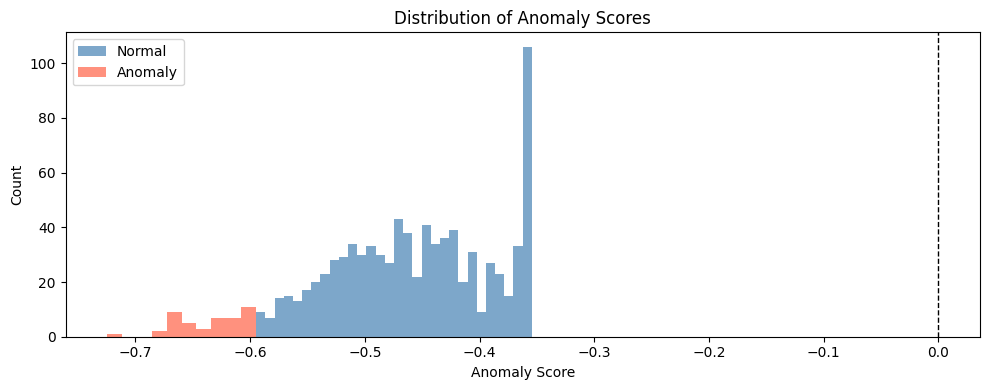


Normal passengers - average score: -0.4541
Anomalous passengers - average score: -0.6342


In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

normal_scores = df[df['anomaly_prediction'] == 1]['anomaly_score']
anomaly_scores = df[df['anomaly_prediction'] == -1]['anomaly_score']

plt.hist(normal_scores, bins=30, alpha=0.7, label='Normal', color='steelblue')
plt.hist(anomaly_scores, bins=10, alpha=0.7, label='Anomaly', color='tomato')

plt.xlabel('Anomaly Score')
plt.ylabel('Count')
plt.title('Distribution of Anomaly Scores')
plt.legend()
plt.axvline(x=0, color='black', linestyle='--', linewidth=1, label='Score = 0')
plt.tight_layout()
plt.show()

print("\nNormal passengers - average score:", round(normal_scores.mean(), 4))
print("Anomalous passengers - average score:", round(anomaly_scores.mean(), 4))

In [6]:
print("=== CONTAMINATION EXPERIMENT ===\n")

for c in [0.01, 0.05, 0.10, 0.20]:
    m = IsolationForest(n_estimators=100, contamination=c, random_state=42)
    m.fit(X)
    preds = m.predict(X)
    n_anomalies = (preds == -1).sum()
    pct = (n_anomalies / len(X)) * 100
    print(f"contamination={c:.2f}  →  flagged {n_anomalies:3d} anomalies ({pct:.1f}% of data)")

=== CONTAMINATION EXPERIMENT ===

contamination=0.01  →  flagged   8 anomalies (0.9% of data)
contamination=0.05  →  flagged  45 anomalies (5.1% of data)
contamination=0.10  →  flagged  89 anomalies (10.0% of data)
contamination=0.20  →  flagged 178 anomalies (20.0% of data)


In [7]:
model_final = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
model_final.fit(X)

typical_passenger = pd.DataFrame(
    [[3, 0, 25, 0, 0, 8.0, 0]],
    columns=features
)

unusual_passenger = pd.DataFrame(
    [[1, 1, 2, 5, 3, 512.0, 1]],
    columns=features
)

for name, p in [("Typical passenger", typical_passenger),
                ("Unusual passenger", unusual_passenger)]:
    pred = model_final.predict(p)[0]
    score = model_final.score_samples(p)[0]
    label = "ANOMALY" if pred == -1 else "NORMAL"
    print(f"{name}:")
    print(f"  Prediction: {label}")
    print(f"  Anomaly score: {score:.4f}")
    print(f"  (more negative = more anomalous)")
    print()

Typical passenger:
  Prediction: NORMAL
  Anomaly score: -0.3568
  (more negative = more anomalous)

Unusual passenger:
  Prediction: ANOMALY
  Anomaly score: -0.7516
  (more negative = more anomalous)



## Day 9 Summary — Isolation Forest

### How it works
- Builds 100 random trees of cuts through the data
- Points that are easy to isolate (few cuts needed) = anomalies
- Points that are hard to isolate (many cuts needed) = normal

### Key parameters
- n_estimators: number of trees. More = more stable. Default 100 is fine.
- contamination: % of data expected to be anomalous. 
  This is the main tuning knob.
- random_state: makes results reproducible

### Anomaly score
- score_samples() returns a float
- Close to -1 = very anomalous
- Close to 0 = borderline
- Positive = very normal

### For WASS
- Train on NORMAL HTTP requests only
- Score each incoming request
- Return score + label to the scanner
- Severity scorer uses the magnitude to grade the finding